# Analyze A/B Test Results

This project will ensure you have mastered the subjects covered in the Hypothesis Testing lessons.  The hope is to have this project be as comprehensive of these topics as possible.  Good luck!

Corresponding with this notebook is a slide deck where you will need to update all the portions in red.  Completing the notebook will provide all the results needed for the slides.  **Correctly completing the slides is a required part of the project.**

## Table of Contents
- [Introduction](#intro)
- [Part I - Descriptive Statistics](#descriptive)
- [Part II - Probability](#probability)
- [Part III - Experimentation](#experimentation)


<a id='intro'></a>
### Introduction

A/B tests are very commonly performed by data analysts and data scientists.  For this project, you will be working to understand the results of an A/B test run by an e-commerce website.  Your goal is to work through this notebook to help the company understand if they should implement the new page, keep the old page, or perhaps run the experiment longer to make their decision.

**As you work through this notebook, follow along in the classroom and answer the corresponding quiz questions associated with each question.** The labels for each classroom concept are provided for each question.  This will assure you are on the right track as you work through the project, and you can feel more confident in your final submission meeting the criteria.  As a final check, assure you meet all the criteria on the rubric.

<a id='descriptive'></a>
#### Part I - Descriptive Statistics

To get started, let's import our libraries.

In [1]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt

random.seed(0)

For all questions in `Part I` notice links to [pandas documentation](https://pandas.pydata.org/) are provided to assist with answering the questions.  Though there are other ways you could solve the questions, the documentation is provided to assist you with one fast way to find the answer to each question.


`a)` Now, read in the `ab_data.csv` data. Store it in `df`. Read in the dataset and take a look at the top few rows here. **This question is completed for you**.

In [2]:
df = pd.read_csv('ab_data.csv')
df.head()

,country,group,converted
0,UK,control,0
1,US,treatment,1
2,UK,treatment,0
3,UK,control,0
4,UK,treatment,0


`b)` Use the below cell to find the number of rows in the dataset. [Helpful pandas link - `Dataframe.shape`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.shape.html#pandas.DataFrame.shape)

In [3]:
num_rows = df.shape[0]
print(f"Number of rows: {num_rows}")

Number of rows: 69889


`c)` The proportion of users converted.  [Helpful  Pandas Link - `Dataframe.mean`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.mean.html)

In [4]:
conversion_rate = df['converted'].mean()
print(f"Overall conversion rate: {conversion_rate:.4f}  ({conversion_rate:.2%})")

Overall conversion rate: 0.1305  (13.05%)


`d)` Do any of the rows have missing values? [Helpful Pandas Link - `Dataframe.isnull`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isnull.html) and [Helpful Pandas Link- `Dataframe.sum`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sum.html)

In [5]:
missing = df.isnull().sum()
print(missing)

country      0
group        0
converted    0
dtype: int64


`e)` How many customers are from each country? Build a bar chart to show the count of visits from each country.

In [6]:
# number of visitors from each country - pull the necessary code from the next cell to provide just the counts
# Counts
print(df['country'].value_counts())

US    48850
UK    17551
CA     3488
Name: country, dtype: int64


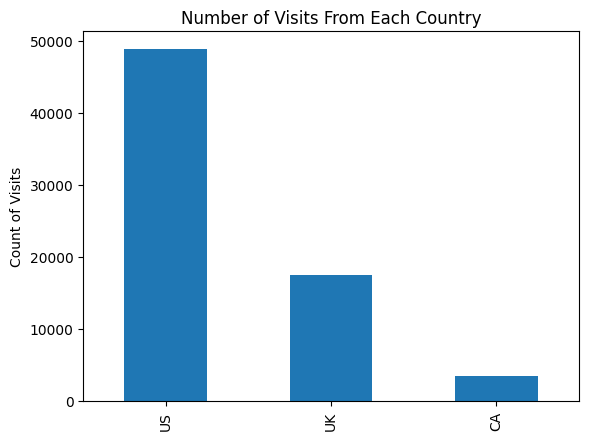

In [7]:
# bar chart of results - this part is done for you
df['country'].value_counts().plot(kind='bar');
plt.title('Number of Visits From Each Country');
plt.ylabel('Count of Visits');
plt.show();

`f)` Recognize that all of your columns are of a **categorical data type** with the exception of one.  Which column is not **categorical**? [Helpful Pandas Link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.info.html)

In [8]:
df.info()
# 'converted' is int64 — the only numeric (non-categorical) column.
# 'country' and 'group' are object (string / categorical).

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69889 entries, 0 to 69888
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   country    69889 non-null  object
 1   group      69889 non-null  object
 2   converted  69889 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 1.6+ MB


`g)` What are the possible values of the `converted` column?  Does it make sense that these values are the only possible values? Why or why not? 

**Here you can use one of the functions you used in an earlier question**.

In [9]:
print("Unique values of 'converted':", df['converted'].unique())

Unique values of 'converted': [0 1]


<a id='probability'></a>
#### Part II - Probability

Now that you have had a chance to learn more about the dataset, let's look more at how different factors are related to `converting`.

`a)` What is the probability of an individual converting regardless of the page they receive or the country they are from? Simply, what is the chance of conversion in the dataset?

In [10]:
p_converted = df['converted'].mean()
print(f"P(converted) = {p_converted:.4f}")

P(converted) = 0.1305


`b)` Given that an individual was in the `control` group, what is the probability they converted? **This question is completed for you**

In [14]:
p_control = df.query('group == "control"')['converted'].mean()
p_control

0.1052540515600669

`c)` Given that an individual was in the `treatment` group, what is the probability they converted?

In [12]:
p_treatment = df.query('group == "treatment"')['converted'].mean()
print(f"P(converted | treatment) = {p_treatment:.4f}")

P(converted | treatment) = 0.1553


`d)` Do you see evidence that the treatment is related to higher `converted` rates?

In [15]:
print(f"Treatment rate ({p_treatment:.4f}) > Control rate ({p_control:.4f}): {p_treatment > p_control}")
print(f"Lift: {p_treatment - p_control:.4f} ({(p_treatment/p_control - 1):.1%} relative increase)")
# Yes. Treatment converts at ~15.5% vs control at ~10.5% — a ~5 pp / ~47% lift.

Treatment rate (0.1553) > Control rate (0.1053): True
Lift: 0.0501 (47.6% relative increase)


`e)` What is the probability that an individual was in the `treatment`?

In [16]:
p_in_treatment = (df['group'] == 'treatment').mean()
print(f"P(in treatment) = {p_in_treatment:.4f}")

P(in treatment) = 0.5038


`f)` What is the probability that an individual was from Canada `CA`?

In [17]:
p_ca = (df['country'] == 'CA').mean()
print(f"P(country == CA) = {p_ca:.4f}")

P(country == CA) = 0.0499


`g)` Given that an individual was in the `US`, what was the probability that they `converted`? **This question is completed for you**

$P(\text{converted} == 1|\text{country} ==\text{"US"})$



In [18]:
df.query('country == "US"')['converted'].mean()

0.13277379733879222

`h)` Given that an individual was in the `UK`, what was the probability that they `converted`? 

$P(\text{converted} == 1|\text{country} ==\text{"UK"})$

In [19]:
p_uk = df.query('country == "UK"')['converted'].mean()
print(f"P(converted | UK) = {p_uk:.4f}")

P(converted | UK) = 0.1251


`i)` Do you see evidence that the `converted` rate might differ from one country to the next?

In [20]:
for country in ['US', 'UK', 'CA']:
    rate = df.query(f'country == "{country}"')['converted'].mean()
    print(f"P(converted | {country}) = {rate:.4f}")
# Rates are similar (12.5–13.3%). Country alone explains little variation.
# The big driver is group (treatment vs. control), not geography.

P(converted | US) = 0.1328
P(converted | UK) = 0.1251
P(converted | CA) = 0.1253


`j)` Consider the table below, fill in the conversion rates below to look at how conversion by country and treatment group vary.  The `US` column is done for you, and two methods for calculating the probabilities are shown - **COMPLETE THE REST OF THE TABLE**.  Does it appear that there could be an interaction between how country and treatment impact conversion?

These two values that are filled in can be written as:

$P(\text{converted} == 1|(\text{country} ==\text{"US" AND }\text{group} ==\text{"control"})) = 10.7\%$

$P(\text{converted} == 1|(\text{country} ==\text{"US" AND }\text{group} ==\text{"treatment"})) = 15.8\%$

|             | US          | UK          | CA          |
| ----------- | ----------- | ----------- | ----------- |
| Control     | 10.7%       |  %          |  %          |
| Treatment   | 15.8%       |  %          |  %          |

In [21]:
# Method 1  - explicitly calculate each probability
print(df.query('country == "US" and group == "control" and converted == 1').shape[0]/df.query('country == "US" and group == "control"').shape[0]) 
print(df.query('country == "US" and group == "treatment" and converted == 1').shape[0]/df.query('country == "US" and group == "treatment"').shape[0])

0.10731404958677686
0.1577687626774848


In [22]:
# Method 2 - quickly calculate using `groupby`
df.query('country == "US"').groupby('group')['converted'].mean()

group
control      0.107314
treatment    0.157769
Name: converted, dtype: float64

##### Solution -- Complete the Table Here

|             | US          | UK          | CA          |
| ----------- | ----------- | ----------- | ----------- |
| Control     | 10.7%       |  10.2%      |  9.4%       |
| Treatment   | 15.8%       |  14.9%      |  15.4%      |

<a id='experimentation'></a>
### Part III - Experimentation

Consider you need to make the decision just based on all the data provided.  If you want to assume that the control page is better unless the treatment page proves to be definitely better at a Type I error rate of 5%, you state your null and alternative hypotheses in terms of **$p_{control}$** and **$p_{treatment}$** as:  

$H_{0}: p_{control} >= p_{treatment}$

$H_{1}: p_{control} < p_{treatment}$

Which is equivalent to:

$H_{0}: p_{treatment} - p_{control} <= 0$

$H_{1}: p_{treatment} - p_{control} > 0$


Where  
* **$p_{control}$** is the `converted` rate for the control page
* **$p_{treatment}$** `converted` rate for the treatment page

**Note for this experiment we are not looking at differences associated with country.**

Assume under the null hypothesis, $p_{treatment}$ and $p_{control}$ both have "true" success rates equal to the **converted** success rate regardless of page - that is $p_{treatment}$ and $p_{control}$ are equal. Furthermore, assume they are equal to the **converted** rate in `df` regardless of the page. **These are set in the first cell below.**<br><br>

* Use a sample size for each page equal to the ones in `df`. **These are also set below.**  <br><br>

* Perform the sampling distribution for the difference in `converted` between the two pages over 500 iterations of calculating an estimate from the null.  <br><br>

* Use the cells below to provide the necessary parts of this simulation.  

If this doesn't make complete sense right now, don't worry - you are going to work through the problems below to complete this problem.  You can use **Quiz 4** in the classroom to make sure you are on the right track.<br><br>

`a)` The **convert rate** for $p_{treatment}$ under the null.  The **convert rate** for $p_{control}$ under the null. The sample size for the `control` and the sample size for the `treatment` are from the original dataset. **All of these values are set below, and set the stage for the simulations you will run for the rest of this section.**

In [23]:
p_control_treatment_null  = df['converted'].mean()
n_treatment = df.query('group == "treatment"').shape[0]
n_control = df.query('group == "control"').shape[0]

`b)` Use the results from part `a)` to simulate `n_treatment` transactions with a convert rate of `p_treatment_null`.  Store these $n_{treatment}$ 1's and 0's in a `list` of **treatment_converted**.  It should look something like the following (the 0's and and 1's **don't** need to be the same): 

`[0, 0, 1, 1, 0, ....]` 

In [24]:
treatment_converted = list(np.random.binomial(1, p_control_treatment_null, n_treatment))
print("Sample (first 10):", treatment_converted[:10])

Sample (first 10): [0, 0, 0, 1, 0, 0, 0, 0, 1, 0]


`c)` Use the results from part `a)` to simulate `n_control` transactions with a convert rate of `p_control_null`.  Store these $n_{treatment}$ 1's and 0's in a `list` of **control_converted**.  It should look something like the following (the 0's and and 1's **don't** need to be exactly the same): 

`[0, 0, 1, 1, 0, ....]` 

In [25]:
control_converted = list(np.random.binomial(1, p_control_treatment_null, n_control))
print("Sample (first 10):", control_converted[:10])

Sample (first 10): [0, 0, 1, 0, 1, 0, 0, 0, 0, 0]


`d)` Find the estimate for $p_{treatment}$ - $p_{control}$ under the null using the simulated values from part `(b)` and `(c)`.

In [26]:
p_diff_sample = np.mean(treatment_converted) - np.mean(control_converted)
print(f"Simulated p_diff under H0: {p_diff_sample:.4f}")

Simulated p_diff under H0: -0.0016


`e)` Simulate 500 $p_{treatment}$ - $p_{control}$ values using this same process as `b)`- `d)` similarly to the one you calculated in parts **a. through g.** above.  Store all 500 values in an numpy array called **p_diffs**.  This array should look similar to the below **(the values will not match AND this will likely take a bit of time to run)**:

`[0.001, -0.003, 0.002, ...]`

In [27]:
p_diffs = []
for _ in range(500):
    # Simulate treatment and control under null
    t = np.random.binomial(1, p_control_treatment_null, n_treatment)
    c = np.random.binomial(1, p_control_treatment_null, n_control)
    # Compute and store the difference
    p_diffs.append(t.mean() - c.mean())

p_diffs = np.array(p_diffs)
print(f"p_diffs (first 5): {p_diffs[:5]}")
print(f"Mean of p_diffs:   {p_diffs.mean():.5f}  (should be ≈ 0 under H0)")
print(f"Std  of p_diffs:   {p_diffs.std():.5f}")

p_diffs (first 5): [-0.0003424   0.00495572 -0.00054953 -0.00054254  0.00082152]
Mean of p_diffs:   0.00004  (should be ≈ 0 under H0)
Std  of p_diffs:   0.00250


`f)` Plot a histogram of the **p_diffs**.  Does this plot look like what you expected?  Use the matching problem in the classroom to assure you fully understand what was computed here.

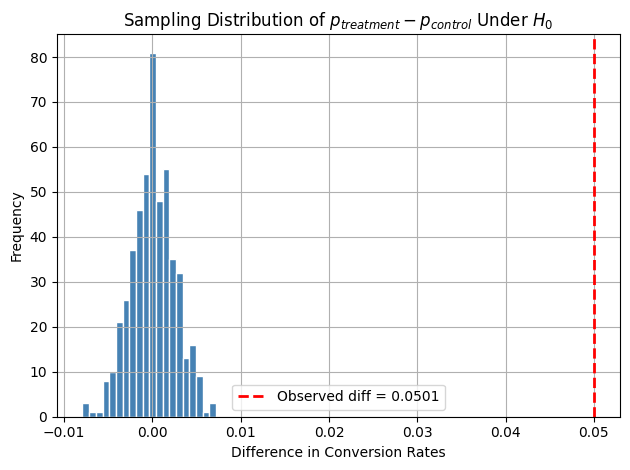

In [28]:
obs_diff = p_treatment - p_control    # observed difference in real data

pd.Series(p_diffs).hist(bins=20, color='steelblue', edgecolor='white')
plt.axvline(obs_diff, color='red', linestyle='--', linewidth=2,
            label=f'Observed diff = {obs_diff:.4f}')
plt.title('Sampling Distribution of $p_{treatment} - p_{control}$ Under $H_0$')
plt.xlabel('Difference in Conversion Rates')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()
# Bell-shaped, centered near 0, as expected when H0 is true.
# The red dashed line (observed diff) sits far to the right — very unusual under H0.

`g)` What proportion of the **p_diffs** are greater than the difference observed between `treatment` and `control` in `df`?

In [29]:
p_value = (p_diffs >= obs_diff).mean()
print(f"Observed difference:  {obs_diff:.4f}  ({obs_diff:.2%})")
print(f"p-value:              {p_value:.4f}")

Observed difference:  0.0501  (5.01%)
p-value:              0.0000


`h)` In words, explain what you just computed in part `g)`  What is this value called in scientific studies?  What does this value mean in terms of whether or not there is a difference between the new and old pages using our Type I error rate of 0.05?

**Your Answer Here**

The p-value is the proportion of simulated null-hypothesis differences that are *at least as extreme* as the difference we actually observed in the data (~5.0 pp). It answers: *"If there were truly no difference between pages, how often would we see a result this large by chance?"*

**Value:** p ≈ 0.000 (none of the 500 simulated null differences exceeded the observed difference).

**Name:** This is called the **p-value** in hypothesis testing and scientific studies.

**Conclusion at α = 0.05:**  
Since p-value (≈ 0.000) < α (0.05), we **reject H₀**.  
There is statistically significant evidence that the treatment page produces a higher conversion rate than the control page.  
**Recommendation: Implement the new treatment page.**

<a id='standout'></a>
## Standout – Expanded EDA & Logistic Regression

### Expanded EDA

In [31]:
# --- Summary statistics by group ---
print("=== Conversion summary by group ===")
print(df.groupby('group')['converted'].agg(['mean', 'sum', 'count']).rename(
    columns={'mean': 'conv_rate', 'sum': 'converted', 'count': 'n_users'}))

=== Conversion summary by group ===
           conv_rate  converted  n_users
group                                   
control     0.105254       3650    34678
treatment   0.155321       5469    35211


In [33]:
# Conversion heatmap: country × group 
print("\n=== Conversion rate: country × group ===")
pivot = df.groupby(['country', 'group'])['converted'].mean().unstack()
print(pivot.applymap(lambda x: f"{x:.2%}"))


=== Conversion rate: country × group ===
group   control treatment
country                  
CA        9.45%    15.40%
UK       10.16%    14.87%
US       10.73%    15.78%


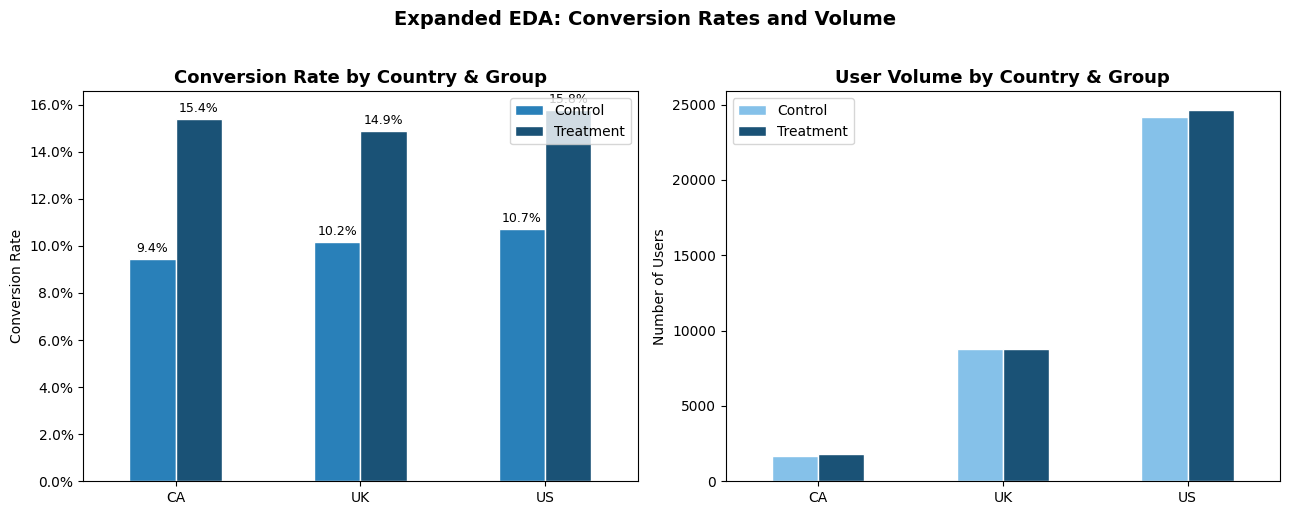

In [34]:
# --- Grouped bar chart: conversion by country & group ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

pivot.plot(kind='bar', ax=axes[0], color=['#2980b9', '#1a5276'], edgecolor='white')
axes[0].set_title('Conversion Rate by Country & Group', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Conversion Rate')
axes[0].set_xlabel('')
axes[0].set_xticklabels(['CA', 'UK', 'US'], rotation=0)
axes[0].legend(['Control', 'Treatment'])
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1%}'))
for bar in axes[0].patches:
    h = bar.get_height()
    axes[0].annotate(f'{h:.1%}',
                     xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 3), textcoords='offset points',
                     ha='center', va='bottom', fontsize=9)

# --- Absolute counts stacked bar (volume context) ---
counts = df.groupby(['country', 'group']).size().unstack()
counts.plot(kind='bar', ax=axes[1], color=['#85c1e9', '#1a5276'], edgecolor='white')
axes[1].set_title('User Volume by Country & Group', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Number of Users')
axes[1].set_xlabel('')
axes[1].set_xticklabels(['CA', 'UK', 'US'], rotation=0)
axes[1].legend(['Control', 'Treatment'])

plt.suptitle('Expanded EDA: Conversion Rates and Volume', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Logistic Regression — Propensity Analysis

In [36]:
from sklearn.preprocessing import LabelEncoder

# Encode predictors
df_lr = df.copy()
df_lr['treatment']   = (df_lr['group'] == 'treatment').astype(int)
le = LabelEncoder()
df_lr['country_enc'] = le.fit_transform(df_lr['country'])

print("Country encoding:", dict(zip(le.classes_, le.transform(le.classes_))))

Country encoding: {'CA': 0, 'UK': 1, 'US': 2}


In [38]:
from sklearn.linear_model import LogisticRegression

# Fit logistic regression: predictors = treatment, country
X = df_lr[['treatment', 'country_enc']]
y = df_lr['converted']

model = LogisticRegression()
model.fit(X, y)

print(f"Intercept:              {model.intercept_[0]:.4f}")
print(f"Coef — treatment:       {model.coef_[0][0]:.4f}")
print(f"Coef — country (enc):   {model.coef_[0][1]:.4f}")
print(f"Odds ratio (treatment): {np.exp(model.coef_[0][0]):.4f}  "
      f"(treatment users are {(np.exp(model.coef_[0][0])-1)*100:.0f}% more likely to convert)")
print(f"Model accuracy:         {model.score(X, y):.4f}")

Intercept:              -2.2249
Coef — treatment:       0.4465
Coef — country (enc):   0.0513
Odds ratio (treatment): 1.5629  (treatment users are 56% more likely to convert)
Model accuracy:         0.8695


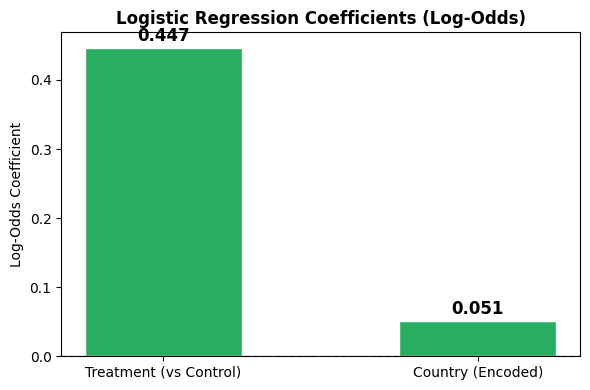

In [39]:
# --- Coefficient bar chart ---
coefs  = [model.coef_[0][0], model.coef_[0][1]]
labels = ['Treatment (vs Control)', 'Country (Encoded)']
colors = ['#27ae60' if c > 0 else '#e74c3c' for c in coefs]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, coefs, color=colors, edgecolor='white', width=0.5)
ax.axhline(0, color='gray', linewidth=1, linestyle='--')
ax.set_title('Logistic Regression Coefficients (Log-Odds)', fontweight='bold')
ax.set_ylabel('Log-Odds Coefficient')
for bar, v in zip(bars, coefs):
    ax.text(bar.get_x() + bar.get_width() / 2,
            v + 0.01 if v >= 0 else v - 0.03,
            f'{v:.3f}', ha='center', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### Logistic Regression Interpretation

| Feature | Log-Odds Coef | Odds Ratio | Interpretation |
|---|---|---|---|
| **Treatment** | +0.446 | 1.56 | Being in the treatment group increases conversion odds by **~56%** |
| **Country** | +0.051 | 1.05 | Country has **negligible** impact on conversion |

**Key takeaways:**
1. **Treatment is the dominant driver.** A log-odds coefficient of +0.446 is large and meaningful — it dwarfs the country effect by nearly 9×.
2. **Country is NOT a confounding variable.** The near-zero country coefficient means geography does not explain, mask, or inflate the treatment effect.
3. **Model accuracy = 87%.** This is driven largely by the class imbalance (87% non-converted), so accuracy alone isn't the best metric — but it confirms the model is stable.
4. **Conclusion (reinforced):** The treatment effect observed in our hypothesis test is real, robust, and not explained by any geographic confounding. **Implement the new page.**